# Differential gene expression in colorectal liver metastases (GSE38174)

**Question:** Which genes differ between colorectal-cancer liver metastases and the surrounding normal liver tissue?

**Data:** GEO series GSE38174, Agilent two-colour microarray (GPL6480). 30 metastasis, 30 halo and 30 liver parenchyma biopsies (6 normal-colon samples are not used).

**Workflow:** load data → preprocessing → sample QC → PCA → differential expression → robustness checks → biological validation → pathway enrichment.

In [1]:
import logging
import os
import warnings

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import GEOparse
import gseapy as gp
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.multitest import multipletests

logging.disable(logging.INFO)  # silence GEOparse's verbose download log
warnings.filterwarnings("ignore", category=pd.errors.DtypeWarning)

for folder in ["../data", "../figures", "../results"]:
    os.makedirs(folder, exist_ok=True)

## 1. Load data from GEO

The series is downloaded with `GEOparse` (the first run downloads a large file into `../data`, later runs reuse it). Each array is **two-colour**: the sample (Cy3) was hybridised together with a Universal Human Reference (Cy5), so every value is a **log2 ratio of sample to reference**, not an absolute expression level.

In [2]:
# Downloads GSE38174 on the first run; later runs use the local copy
gse = GEOparse.get_GEO(geo="GSE38174", destdir="../data")

In [3]:
expr = gse.pivot_samples("VALUE")   # probes x samples
meta = gse.phenotype_data           # one row per sample

print("Expression matrix (probes x samples):", expr.shape)
meta[["title", "source_name_ch1", "description"]].head(3)

Expression matrix (probes x samples): (41093, 96)


,title,source_name_ch1,description
GSM936257,Liver metasis Replicate 1,Liver Biopsy of metasis,Liver biopsy of metasis from subject 1
GSM936258,Liver Halo of metasis Replicate 1,Liver Biopsy of Halo of metasis,Liver biopsy of Halo of metasis from subject 1
GSM936259,Liver parenchyma (control) Replicate 1,Liver Biopsy of parenchyma (control),Liver biopsy of parenchyma (control) from subj...


## 2. Sample groups

Groups are parsed from the sample titles. The replicate number in the title identifies the **subject**: the GEO `description` field reads "... from subject N" (verified below). So each metastasis biopsy has a matching parenchyma biopsy from the same patient.

In [4]:
def get_group(title):
    t = title.lower()
    if "halo" in t:                                   # check "halo" first: "Halo of metasis" contains both words
        return "Halo"
    if "metasis" in t or "metastasis" in t:           # GEO titles use the spelling "metasis"
        return "Metastasis"
    if "parenchyma" in t:
        return "Parenchyma"
    if "colonic" in t:
        return "Colon_normal"
    return "Other"

meta["group"] = meta["title"].apply(get_group)
meta["replicate"] = meta["title"].str.extract(r"Replicate (\d+)")[0].astype(int)
print(meta["group"].value_counts())

group
Metastasis      30
Halo            30
Parenchyma      30
Colon_normal     6
Name: count, dtype: int64


In [5]:
# Check: replicate number == subject ID given in the GEO description
three_groups = meta[meta["group"].isin(["Metastasis", "Halo", "Parenchyma"])]
subject = three_groups["description"].str.extract(r"subject (\d+)")[0].astype(int)
assert (subject == three_groups["replicate"]).all()

### Check the scale of the values

Before any transformation we check the value range. Negative values and a range centred around 0 mean the data are already log2 ratios, so **no further log transform** is applied.

In [6]:
print("min / max:", expr.min().min(), expr.max().max())
print("missing values:", expr.isna().sum().sum())

min / max: -10.176673 12.194785
missing values: 0


## 3. Preprocessing

For the statistical comparison we keep metastasis and parenchyma. Steps: (1) map probes to genes, (2) drop control, unmapped and ambiguous probes, (3) drop the lowest-variance probes, (4) average the remaining probes of each gene. The steps are shown one by one first and then wrapped into a function.

In [7]:
keep = meta.index[meta["group"].isin(["Metastasis", "Parenchyma"])]
expr_probe = expr[keep]                 # probe-level matrix, 60 samples
meta_probe = meta.loc[keep]
assert (expr_probe.columns == meta_probe.index).all()
print(meta_probe["group"].value_counts())

group
Metastasis    30
Parenchyma    30
Name: count, dtype: int64


### Probe-to-gene mapping

The platform annotation table (GPL6480) gives a gene symbol for each probe ID.

In [8]:
platform = list(gse.gpls.keys())[0]
annot = gse.gpls[platform].table
mapping = annot.set_index("ID")["GENE_SYMBOL"]      # probe ID -> gene symbol
annot[["ID", "GENE_SYMBOL", "GENE_NAME"]].head()

,ID,GENE_SYMBOL,GENE_NAME
0,A_23_P100001,FAM174B,"family with sequence similarity 174, member B"
1,A_23_P100011,AP3S2,"adaptor-related protein complex 3, sigma 2 sub..."
2,A_23_P100022,SV2B,synaptic vesicle glycoprotein 2B
3,A_23_P100056,RBPMS2,RNA binding protein with multiple splicing 2
4,A_23_P100074,AVEN,"apoptosis, caspase activation inhibitor"


In [9]:
df = expr_probe.copy()
df["gene"] = df.index.map(mapping)

n_before = df.shape[0]
df = df.dropna(subset="gene")                                    # control probes and probes without a symbol
df = df[df["gene"].astype(str).str.strip() != ""]
df = df[~df["gene"].astype(str).str.contains("///")]             # probes matching several genes are ambiguous

print(f"Probes: {n_before} -> {df.shape[0]}")
print("Unique genes:", df["gene"].nunique())

Probes: 41093 -> 30936
Unique genes: 19595


### Several probes per gene

Many genes are measured by more than one probe, so probes have to be combined into one value per gene.

In [10]:
probes_per_gene = df["gene"].value_counts()
print("Genes with 1 probe:", (probes_per_gene == 1).sum())
print("Genes with >1 probe:", (probes_per_gene > 1).sum())
print("Max probes for one gene:", probes_per_gene.max())
probes_per_gene.describe()

Genes with 1 probe: 11519
Genes with >1 probe: 8076
Max probes for one gene: 14


count    19595.000000
mean         1.578770
std          0.846526
min          1.000000
25%          1.000000
50%          1.000000
75%          2.000000
max         14.000000
Name: count, dtype: float64

Do the probes of the same gene agree? If they correlate strongly, averaging them is justified. We check this for *RPL21*, the gene with the most probes.

In [11]:
rpl21 = df[df["gene"] == "RPL21"].drop(columns="gene")
probe_corr = rpl21.T.corr()
pairs = probe_corr.values[np.triu_indices(len(probe_corr), k=1)]    # each probe pair once

print("RPL21 probes:", len(probe_corr))
print(f"Pairwise correlation: mean {pairs.mean():.2f}, median {np.median(pairs):.2f}, min {pairs.min():.2f}")

RPL21 probes: 14
Pairwise correlation: mean 0.91, median 0.91, min 0.79


### Variance filter and one row per gene

Probes in the lowest variance quartile are dropped. The filter uses the overall variance and **not the group labels**, so it does not bias the later group comparison. Remaining probes are averaged per gene.

In [12]:
probe_var = df.drop(columns="gene").var(axis=1)
df = df[probe_var > probe_var.quantile(0.25)]       # label-free filter
expr_gene = df.groupby("gene").mean()               # average the probes of each gene
print(expr_gene.shape)

(15885, 60)


### Check the normalisation

The medians of all samples should be similar and close to 0.

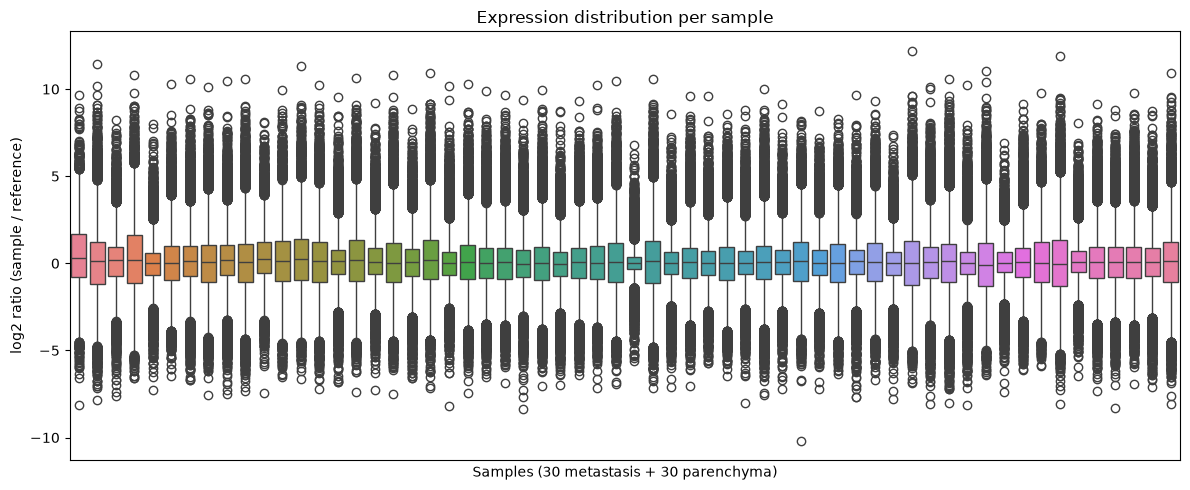

In [13]:
plt.figure(figsize=(12, 5))
sns.boxplot(data=expr_gene)
plt.xticks([])                                      # 60 sample labels are unreadable
plt.xlabel("Samples (30 metastasis + 30 parenchyma)")
plt.ylabel("log2 ratio (sample / reference)")
plt.title("Expression distribution per sample")
plt.tight_layout()
plt.savefig("../figures/boxplot_samples.png", dpi=150)
plt.show()

### The same steps as one function

So the identical pipeline can be applied to different sets of samples: metastasis + parenchyma for the statistics, and additionally halo for QC and PCA.

In [14]:
def preprocess(expr, meta, groups, mapping):
    """Probe-level matrix -> gene-level matrix for the chosen sample groups.

    Select samples, map probes to genes, drop unmapped/ambiguous probes,
    drop the lowest-variance quartile of probes, average probes per gene.
    Returns the gene x sample matrix and the matching metadata.
    """
    keep = meta.index[meta["group"].isin(groups)]
    df = expr[keep].copy()
    df["gene"] = df.index.map(mapping)
    df = df.dropna(subset=["gene"])
    df = df[df["gene"].astype(str).str.strip() != ""]
    df = df[~df["gene"].astype(str).str.contains("///")]
    probe_var = df.drop(columns="gene").var(axis=1)
    df = df[probe_var > probe_var.quantile(0.25)]
    expr_gene = df.groupby("gene").mean()
    return expr_gene, meta.loc[keep]

## 4. Sample QC

For QC and PCA the halo samples are added (90 samples). The pipeline is run again on these 90 samples, so the number of genes differs slightly (the variance quartile is computed on a different set of samples).

In [15]:
groups3 = ["Metastasis", "Halo", "Parenchyma"]
expr_all, meta_all = preprocess(expr, meta, groups3, mapping)
assert (expr_all.columns == meta_all.index).all()
print(expr_all.shape)

palette = {"Metastasis": "tab:red", "Halo": "tab:orange", "Parenchyma": "tab:blue"}

(15897, 90)


### Sample-sample correlation

Samples of the same group should correlate more with each other than with other groups.

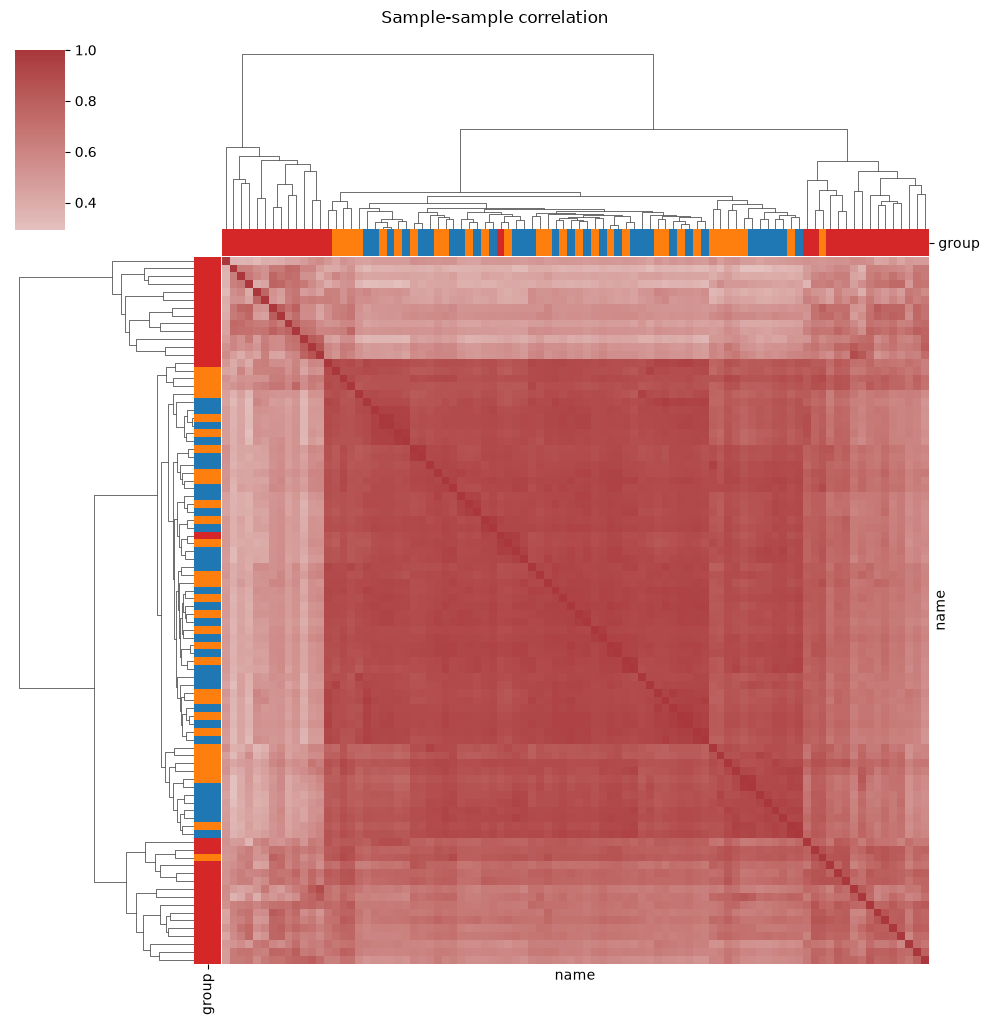

In [16]:
corr = expr_all.corr()                                  # 90 x 90 sample correlation
group_colors = meta_all["group"].map(palette)

g_corr = sns.clustermap(corr, cmap="vlag", center=0,
                        row_colors=group_colors, col_colors=group_colors,
                        figsize=(10, 10), xticklabels=False, yticklabels=False)
g_corr.fig.suptitle("Sample-sample correlation", y=1.02)
g_corr.savefig("../figures/sample_correlation_clustermap.png", dpi=150)

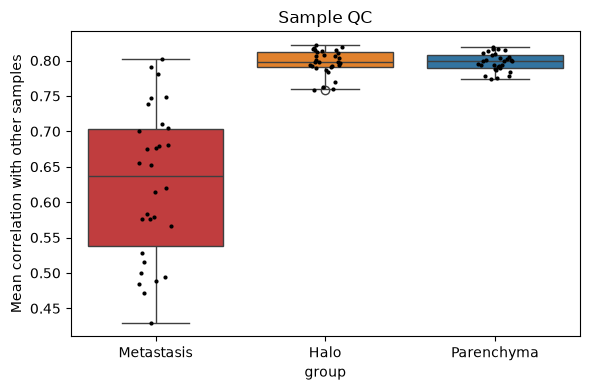

,mean_corr,group
GSM936323,0.429856,Metastasis
GSM936332,0.471269,Metastasis
GSM936296,0.484526,Metastasis
GSM936302,0.488698,Metastasis
GSM936344,0.494241,Metastasis


In [17]:
# Mean correlation of each sample with all other samples (diagonal of 1 removed)
mean_corr = (corr.sum() - 1) / (len(corr) - 1)
qc = pd.DataFrame({"mean_corr": mean_corr, "group": meta_all["group"]})

plt.figure(figsize=(6, 4))
sns.boxplot(data=qc, x="group", y="mean_corr", hue="group", palette=palette, legend=False)
sns.stripplot(data=qc, x="group", y="mean_corr", color="black", size=3)
plt.ylabel("Mean correlation with other samples")
plt.title("Sample QC")
plt.tight_layout()
plt.savefig("../figures/qc_mean_corr.png", dpi=150)
plt.show()

qc.sort_values("mean_corr").head(5)

**Interpretation:** parenchyma and halo samples are very homogeneous (mean correlation ≈ 0.8). Metastases are much more spread out. The five lowest samples are all metastases, i.e. tumours that differ most from liver tissue, which is expected in this comparison. This looks like biological heterogeneity rather than failed arrays, so no sample is removed.

In [18]:
rows = []
for group in ["Metastasis", "Halo", "Parenchyma"]:
    samples = meta_all.index[meta_all["group"] == group]
    group_corr = corr.loc[samples, samples]
    per_sample = (group_corr.sum() - 1) / (len(group_corr) - 1)         # each sample vs the rest of its group
    pairs = group_corr.values[np.triu_indices(len(group_corr), k=1)]    # every sample pair once
    rows.append({"group": group,
                 "mean_per_sample": per_sample.mean(),
                 "min_per_sample": per_sample.min(),
                 "max_per_sample": per_sample.max(),
                 "min_pair": pairs.min(),
                 "max_pair": pairs.max()})

pd.DataFrame(rows).set_index("group").round(2)

,mean_per_sample,min_per_sample,max_per_sample,min_pair,max_pair
group,,,,,
Metastasis,0.65,0.47,0.73,0.33,0.89
Halo,0.88,0.83,0.91,0.74,0.96
Parenchyma,0.90,0.87,0.92,0.78,0.96


## 5. PCA (unsupervised check)

PCA uses no group labels, so it shows whether the groups separate on their own. It is run on the 90 samples in two versions: with only centring of each gene (sklearn does this internally), and with additional per-gene scaling (z-score). If the structure is the same in both, the result does not depend on this choice.

In [19]:
def run_pca(X, scale):
    """PCA on a samples x genes matrix. Returns first 3 PCs with metadata and % variance of 10 PCs."""
    data = StandardScaler().fit_transform(X) if scale else X
    pca = PCA(n_components=10)
    pcs = pca.fit_transform(data)
    var_pct = pca.explained_variance_ratio_ * 100
    pc_df = pd.DataFrame(pcs[:, :3], index=X.index, columns=["PC1", "PC2", "PC3"])
    pc_df["group"] = meta_all["group"]
    pc_df["replicate"] = meta_all["replicate"]
    return pc_df, var_pct


def plot_pca(pc_df, var_pct, name):
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    for ax, (a, b) in zip(axes, [("PC1", "PC2"), ("PC2", "PC3")]):
        sns.scatterplot(data=pc_df, x=a, y=b, hue="group", palette=palette, ax=ax, s=50)
        ax.set_xlabel(f"{a} ({var_pct[int(a[2]) - 1]:.1f}%)")
        ax.set_ylabel(f"{b} ({var_pct[int(b[2]) - 1]:.1f}%)")
        ax.set_title(f"{a} vs {b}")
    plt.tight_layout()
    plt.savefig(f"../figures/pca_{name}.png", dpi=150)
    plt.show()

    plt.figure(figsize=(5, 3.5))
    plt.bar(range(1, 11), var_pct)
    plt.xlabel("PC")
    plt.ylabel("% variance explained")
    plt.title(f"Scree plot ({name})")
    plt.tight_layout()
    plt.savefig(f"../figures/pca_scree_{name}.png", dpi=150)
    plt.show()

No scaling: [38.6 10.4  7. ]
Scaled:     [29.  11.8  7.9]


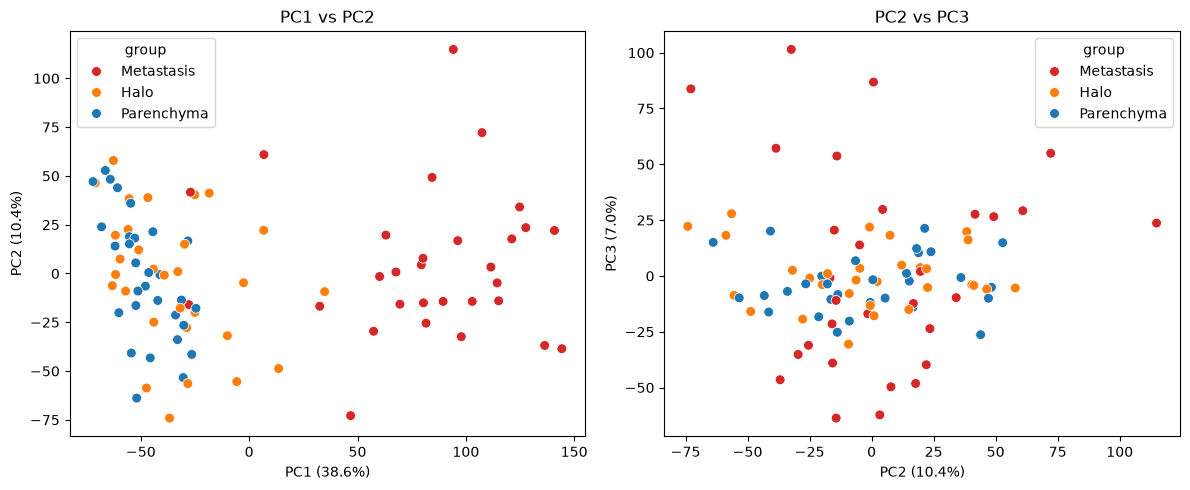

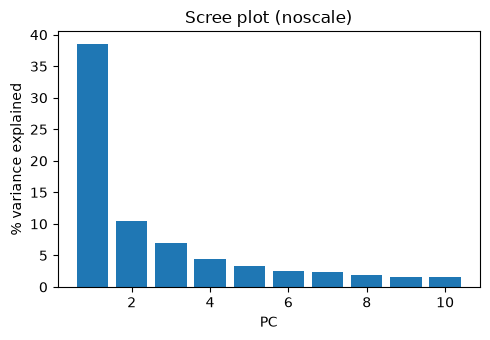

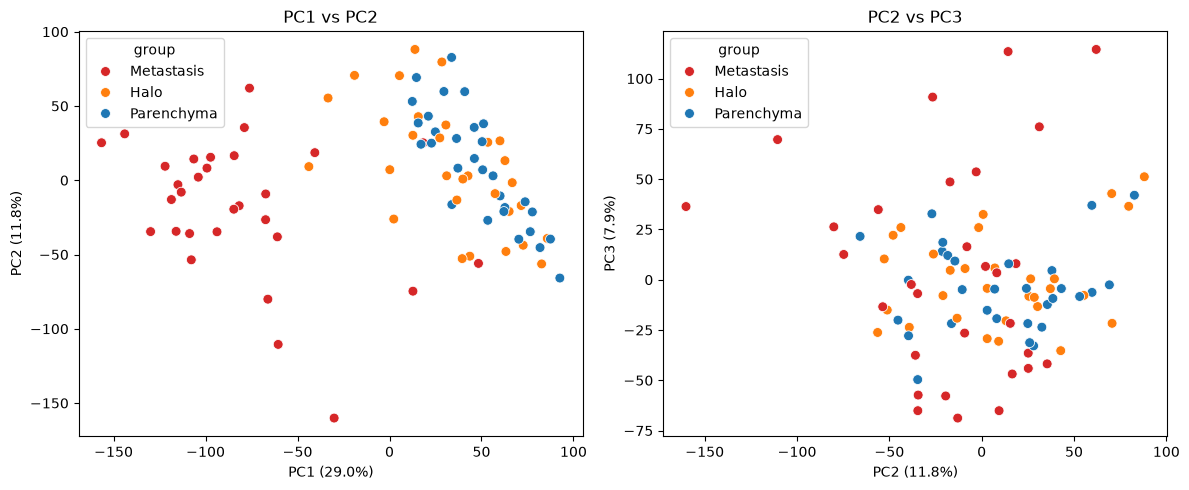

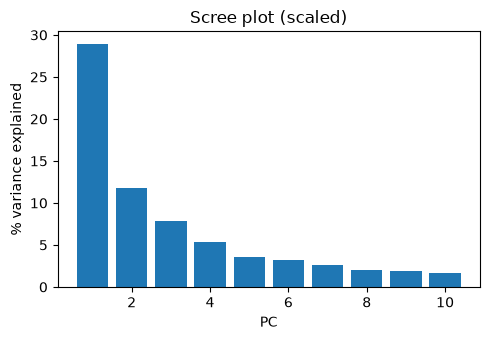

In [20]:
X = expr_all.T                                   # samples x genes

pc_noscale, var_noscale = run_pca(X, scale=False)
pc_scaled, var_scaled = run_pca(X, scale=True)
print("No scaling:", var_noscale[:3].round(1))   # expected [38.6 10.4  7. ]
print("Scaled:    ", var_scaled[:3].round(1))    # expected [29.  11.8  7.9]

plot_pca(pc_noscale, var_noscale, "noscale")
plot_pca(pc_scaled, var_scaled, "scaled")

**Interpretation:** PC1 separates the metastases from the liver tissue (38.6 % of the variance without scaling, 29.0 % with scaling) and the pattern is the same in both versions. Halo samples overlap with parenchyma, i.e. after chemotherapy the halo resembles normal liver. A few metastases lie inside the liver cluster, consistent with low tumour content (a hypothesis that is not tested here). PC2 and PC3 mostly capture variation within the metastases.

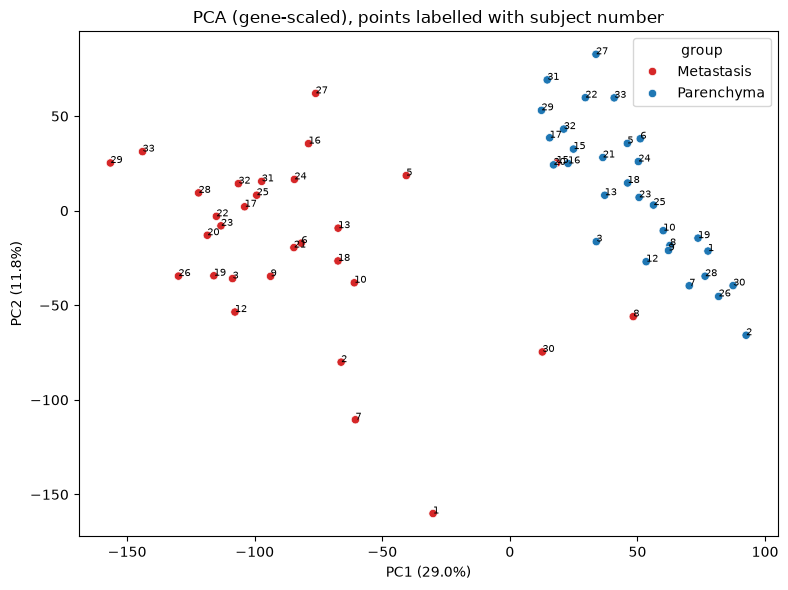

In [21]:
sub = pc_scaled[pc_scaled["group"].isin(["Metastasis", "Parenchyma"])]
plt.figure(figsize=(8, 6))
sns.scatterplot(data=sub, x="PC1", y="PC2", hue="group", palette=palette)
for _, r in sub.iterrows():
    plt.text(r["PC1"], r["PC2"], str(int(r["replicate"])), fontsize=7)    # label = subject number
plt.xlabel(f"PC1 ({var_scaled[0]:.1f}%)")
plt.ylabel(f"PC2 ({var_scaled[1]:.1f}%)")
plt.title("PCA (gene-scaled), points labelled with subject number")
plt.tight_layout()
plt.savefig("../figures/pca_replicate_labels.png", dpi=150)
plt.show()

Samples from the same subject do not lie next to each other, so tissue type dominates over the subject effect.

             PC1   PC2       group  replicate
name                                         
GSM936323  140.9  22.0  Metastasis         26
GSM936332  136.4 -36.9  Metastasis         29
GSM936296   80.4 -15.0  Metastasis         17
GSM936302  121.2  17.7  Metastasis         19
GSM936344  144.3 -38.5  Metastasis         33


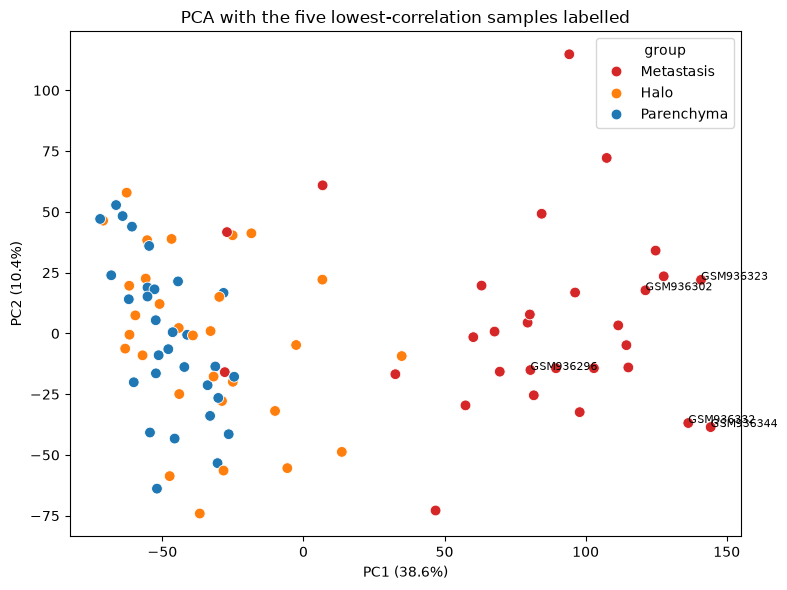

In [22]:
# The five samples with the lowest mean correlation (from the QC step)
low_corr = qc.sort_values("mean_corr").head(5).index.tolist()
print(pc_noscale.loc[low_corr, ["PC1", "PC2", "group", "replicate"]].round(1))

plt.figure(figsize=(8, 6))
sns.scatterplot(data=pc_noscale, x="PC1", y="PC2", hue="group", palette=palette, s=60)
for sample in low_corr:
    plt.text(pc_noscale.loc[sample, "PC1"], pc_noscale.loc[sample, "PC2"], sample, fontsize=8)
plt.xlabel(f"PC1 ({var_noscale[0]:.1f}%)")
plt.ylabel(f"PC2 ({var_noscale[1]:.1f}%)")
plt.title("PCA with the five lowest-correlation samples labelled")
plt.tight_layout()
plt.show()

The five lowest-correlation samples are all metastases and lie on the tumour side of PC1: they are tumours that differ strongly from liver tissue, not technical outliers. No sample was removed.

## 6. Differential expression: metastasis vs parenchyma

Per gene: log2FC = mean(metastasis) − mean(parenchyma). Both groups are log2 ratios to the same reference, so this difference is the log2 fold change between the groups. Test: Welch's t-test (no equal-variance assumption, which matters because metastases are more heterogeneous), then Benjamini–Hochberg FDR over all tested genes.

In [23]:
expr_mp, meta_mp = preprocess(expr, meta, ["Metastasis", "Parenchyma"], mapping)    # gene-level, 60 samples
met_samples = meta_mp.index[meta_mp["group"] == "Metastasis"]
par_samples = meta_mp.index[meta_mp["group"] == "Parenchyma"]
met = expr_mp[met_samples]
par = expr_mp[par_samples]
print("Genes x samples:", expr_mp.shape)                       # (15885, 60)
print("Metastasis:", met.shape, "| Parenchyma:", par.shape)

Genes x samples: (15885, 60)
Metastasis: (15885, 30) | Parenchyma: (15885, 30)


In [24]:
t_stat, p_val = stats.ttest_ind(met, par, axis=1, equal_var=False)    # Welch, one test per gene

res = pd.DataFrame({
    "log2FC": met.mean(axis=1) - par.mean(axis=1),
    "t": t_stat,
    "pval": p_val,
}, index=expr_mp.index)

res["FDR"] = multipletests(res["pval"], method="fdr_bh")[1]           # Benjamini-Hochberg over all genes
res["neg_log10_FDR"] = -np.log10(res["FDR"])
res = res.sort_values("pval")
res.head(10)

,log2FC,t,pval,FDR,neg_log10_FDR
gene,,,,,
PBX4,2.821647,18.181202,5.325388e-25,8.459379e-21,20.072662
TRAF5,3.473288,19.590914,7.109743e-24,5.646913e-20,19.248189
TMEM159,3.056579,17.835363,6.749912e-23,3.574078e-19,18.446836
VGLL4,1.343756,15.667129,3.906962e-22,1.551552e-18,17.809234
S100A11,2.217150,16.631306,6.779095e-22,2.153718e-18,17.666811
MTHFD2,3.132821,15.230470,9.396195e-22,2.487643e-18,17.604212
GSTP1,3.103433,18.331651,1.162458e-21,2.637950e-18,17.578733
SLC25A24,2.730856,15.449942,1.403988e-21,2.787794e-18,17.554739
C1orf198,1.425478,15.196148,2.343920e-21,4.137019e-18,17.383313


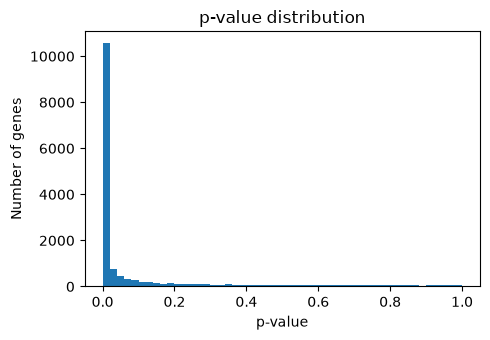

In [25]:
plt.figure(figsize=(5, 3.5))
plt.hist(res["pval"], bins=50)
plt.xlabel("p-value")
plt.ylabel("Number of genes")
plt.title("p-value distribution")
plt.tight_layout()
plt.savefig("../figures/pvalue_hist.png", dpi=150)
plt.show()

A strong peak near 0 and a flat tail is what we expect when there is real signal and the test behaves correctly.

Significant genes: FDR < 0.05 **and** |log2FC| > 1.5 (statistical significance plus a minimum effect size; the effect-size threshold is an arbitrary but common choice).

In [26]:
FDR_CUTOFF = 0.05
LFC_CUTOFF = 1.5

sig_w = (res["FDR"] < FDR_CUTOFF) & (res["log2FC"].abs() > LFC_CUTOFF)
res["status"] = "NS"
res.loc[sig_w & (res["log2FC"] > 0), "status"] = "Up in metastasis"
res.loc[sig_w & (res["log2FC"] < 0), "status"] = "Down in metastasis"
res["status"].value_counts()

status
NS                    13925
Down in metastasis     1038
Up in metastasis        922
Name: count, dtype: int64

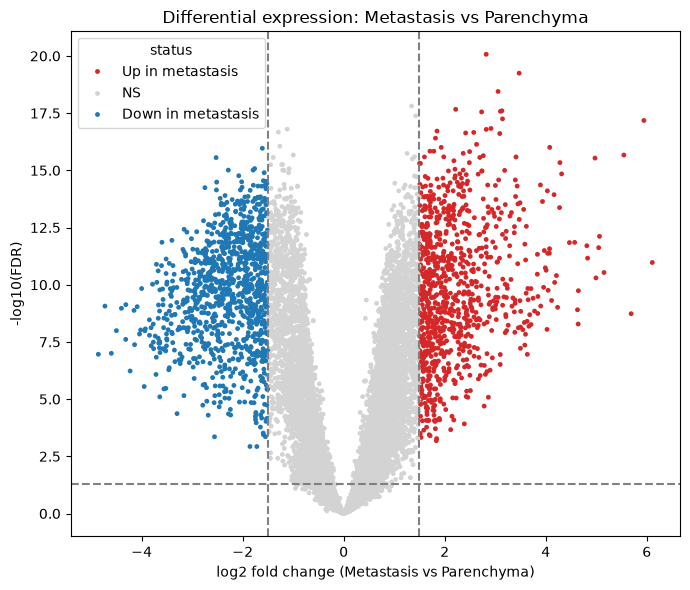

In [27]:
colors_v = {"NS": "lightgrey", "Up in metastasis": "tab:red", "Down in metastasis": "tab:blue"}

plt.figure(figsize=(7, 6))
sns.scatterplot(data=res, x="log2FC", y="neg_log10_FDR",
                hue="status", palette=colors_v, s=12, linewidth=0)
plt.axvline(LFC_CUTOFF, ls="--", c="grey")           # effect-size thresholds
plt.axvline(-LFC_CUTOFF, ls="--", c="grey")
plt.axhline(-np.log10(FDR_CUTOFF), ls="--", c="grey")   # FDR threshold
plt.xlabel("log2 fold change (Metastasis vs Parenchyma)")
plt.ylabel("-log10(FDR)")
plt.title("Differential expression: Metastasis vs Parenchyma")
plt.tight_layout()
plt.savefig("../figures/volcano.png", dpi=150)
plt.show()

## 7. Robustness: other tests

The same comparison is repeated with a non-parametric test (Mann–Whitney) and with a paired t-test. The biopsies come in pairs from the same subject (replicate number = subject ID), so the paired test matches the study design.

In [28]:
u_stat, p_mw = stats.mannwhitneyu(met, par, axis=1)
res["pval_mw"] = pd.Series(p_mw, index=expr_mp.index)
res["FDR_mw"] = multipletests(res["pval_mw"], method="fdr_bh")[1]
sig_mw = (res["FDR_mw"] < FDR_CUTOFF) & (res["log2FC"].abs() > LFC_CUTOFF)

rho = res["pval"].corr(res["pval_mw"], method="spearman")
print("Mann-Whitney significant genes:", sig_mw.sum())
print("Spearman correlation of raw p-values (Welch vs Mann-Whitney):", round(rho, 2))

Mann-Whitney significant genes: 1960
Spearman correlation of raw p-values (Welch vs Mann-Whitney): 0.98


In [29]:
# Pair the biopsies by subject: sort both groups by replicate number so the columns line up
rep_met = meta_mp.loc[met_samples, "replicate"].sort_values()
rep_par = meta_mp.loc[par_samples, "replicate"].sort_values()
assert (rep_met.values == rep_par.values).all()          # same 30 subjects in both groups

t_p, p_p = stats.ttest_rel(met[rep_met.index], par[rep_par.index], axis=1)
res["pval_paired"] = pd.Series(p_p, index=expr_mp.index)
res["FDR_paired"] = multipletests(res["pval_paired"], method="fdr_bh")[1]
sig_p = (res["FDR_paired"] < FDR_CUTOFF) & (res["log2FC"].abs() > LFC_CUTOFF)
print("Paired t-test significant genes:", sig_p.sum())

Paired t-test significant genes: 1960


In [30]:
summary = pd.DataFrame({
    "FDR only": [(res["FDR"] < FDR_CUTOFF).sum(),
                 (res["FDR_mw"] < FDR_CUTOFF).sum(),
                 (res["FDR_paired"] < FDR_CUTOFF).sum()],
    "FDR + |log2FC|": [sig_w.sum(), sig_mw.sum(), sig_p.sum()],
}, index=["Welch", "Mann-Whitney", "Paired t-test"])
print(summary)
print("Identical gene sets:", sig_w.equals(sig_mw) and sig_w.equals(sig_p))

               FDR only  FDR + |log2FC|
Welch             11167            1960
Mann-Whitney      11392            1960
Paired t-test     12132            1960
Identical gene sets: True


All three tests give exactly the same 1,960 genes once the effect-size filter is applied, so the result does not depend on the choice of test.

## 8. Biological sanity check

Liver-specific genes should be lower and colorectal epithelial genes higher in a colon-derived tumour growing in the liver.

In [31]:
liver_genes = ["ALB", "APOA1", "APOA2", "CYP3A4", "CYP2E1", "TF", "SERPINA1"]
crc_genes = ["CEACAM5", "CDX2", "KRT20", "LGR5", "EPCAM", "CDH17", "VIL1"]
cols = ["log2FC", "FDR", "status"]

print("Liver-specific genes (expected: down in metastasis)")
display(res.loc[res.index.intersection(liver_genes), cols])
print("Colorectal epithelial genes (expected: up in metastasis)")
display(res.loc[res.index.intersection(crc_genes), cols])

Liver-specific genes (expected: down in metastasis)


,log2FC,FDR,status
gene,,,
TF,-1.937078,4.691786e-08,Down in metastasis
CYP3A4,-1.833734,5.481751e-08,Down in metastasis
APOA2,-3.762039,6.219836e-08,Down in metastasis
SERPINA1,-1.828346,2.560594e-07,Down in metastasis
APOA1,-2.750770,2.244672e-06,Down in metastasis
ALB,-2.715134,3.156488e-06,Down in metastasis
CYP2E1,-1.480683,2.748029e-04,NS


Colorectal epithelial genes (expected: up in metastasis)


,log2FC,FDR,status
gene,,,
EPCAM,6.109452,1.065795e-11,Up in metastasis
CDX2,2.950498,1.015765e-09,Up in metastasis
KRT20,3.666319,6.503236e-09,Up in metastasis
CEACAM5,3.500677,7.083116e-09,Up in metastasis
CDH17,3.499266,5.998703e-08,Up in metastasis
VIL1,1.711229,3.987585e-04,Up in metastasis
LGR5,0.677416,1.827733e-02,NS


**Interpretation:** 6 of 7 liver genes are down and 6 of 7 colorectal genes are up, as expected. *CYP2E1* (log2FC −1.48) and *LGR5* (+0.68) fall short of the effect-size threshold, which shows that the final gene list depends on this arbitrary cut-off. The down-regulated side mostly reflects missing liver tissue, not cancer-specific biology.

## 9. Top 40 genes

The 20 most up- and 20 most down-regulated significant genes (ranked by log2FC), z-scored per gene.

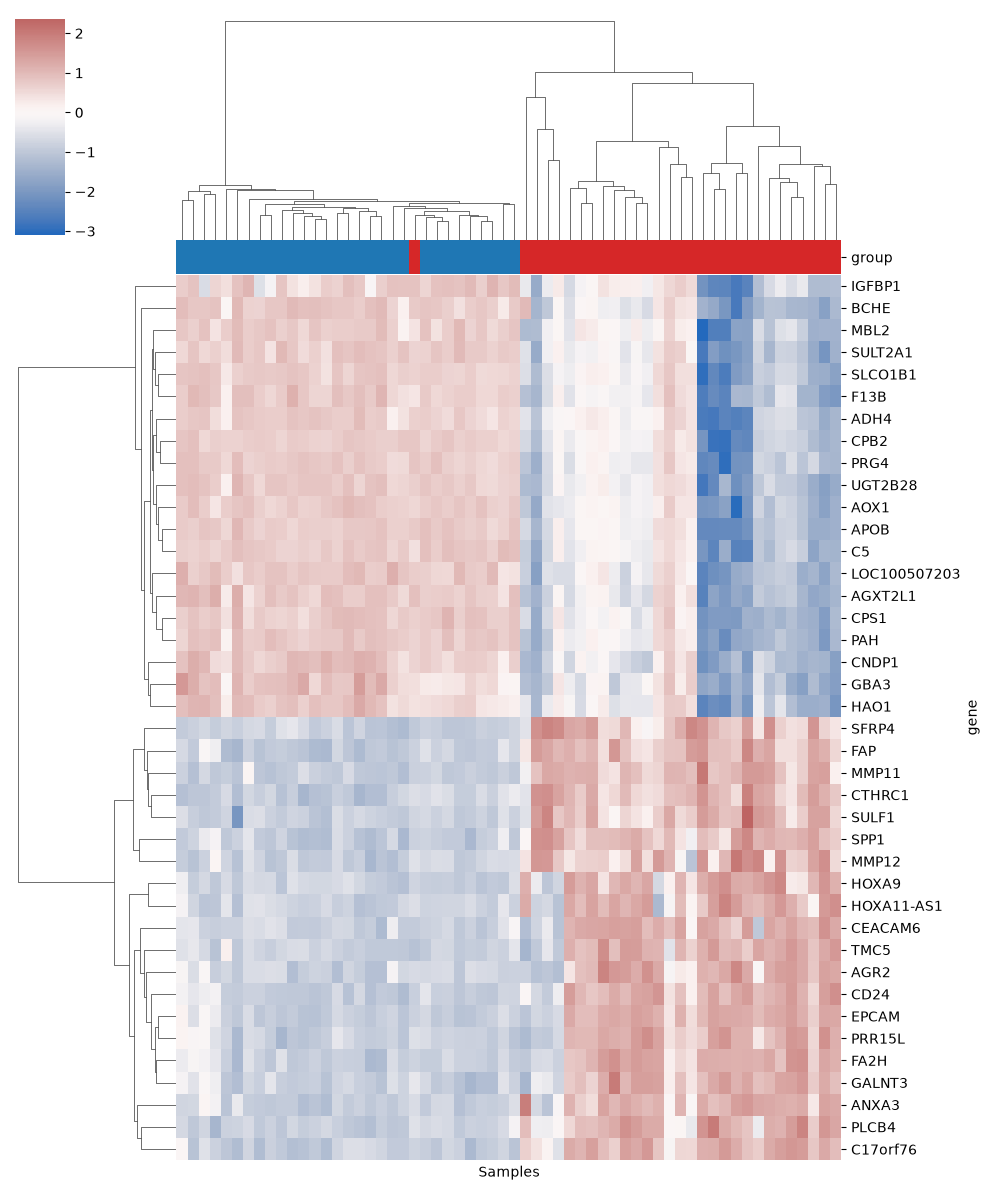

In [32]:
sig_df = res[res["status"] != "NS"]
top_up = sig_df[sig_df["status"] == "Up in metastasis"].nlargest(20, "log2FC").index
top_down = sig_df[sig_df["status"] == "Down in metastasis"].nsmallest(20, "log2FC").index
top_genes = list(top_up) + list(top_down)

hm = expr_mp.loc[top_genes]
order = list(met_samples) + list(par_samples)
hm = hm[order]
col_colors = meta_mp.loc[order, "group"].map(palette)

g_hm = sns.clustermap(hm, z_score=0, cmap="vlag", center=0,
                      col_colors=col_colors, figsize=(10, 12),
                      xticklabels=False, yticklabels=True)
g_hm.ax_heatmap.set_xlabel("Samples")
g_hm.savefig("../figures/heatmap_top40.png", dpi=150)

These genes were selected *because* they differ between the groups, so the clean separation of the columns is expected and is not independent evidence. The unsupervised PCA above is the unbiased check.

In [33]:
# Which metastasis clusters with the liver samples in the heatmap?
ordered_samples = hm.columns[g_hm.dendrogram_col.reordered_ind]
labels = meta_mp.loc[ordered_samples, "group"].values
last_par_pos = max(i for i, x in enumerate(labels) if x == "Parenchyma")
odd = [s for i, s in enumerate(ordered_samples) if labels[i] == "Metastasis" and i < last_par_pos]

print("Metastasis clustering with liver:", odd)           # expected ['GSM936290']
meta_mp.loc[odd, ["title", "replicate"]]

Metastasis clustering with liver: ['GSM936290']


,title,replicate
GSM936290,Liver metasis Replicate 15,15


## 10. Sensitivity: one metastasis that clusters with liver

This sample probably has low tumour content. The test is repeated without it to check that the result does not depend on a single sample.

In [34]:
met2 = met.drop(columns=odd)

t2, p2 = stats.ttest_ind(met2, par, axis=1, equal_var=False)
fdr2 = multipletests(p2, method="fdr_bh")[1]
lfc2 = met2.mean(axis=1) - par.mean(axis=1)
sig2 = (fdr2 < FDR_CUTOFF) & (lfc2.abs() > LFC_CUTOFF)

print("with sample:", sig_w.sum(), "| without sample:", sig2.sum())    # 1960 | 2081
print("genes kept:", (sig_w & sig2).sum(), "| genes added:", (sig2 & ~sig_w).sum())

with sample: 1960 | without sample: 2081
genes kept: 1960 | genes added: 121


Removing the sample keeps all 1,960 genes and adds 121 that now pass the threshold, so the result does not depend on this one sample.

## 11. Pathway enrichment

Up- and down-regulated genes are analysed separately, because opposite signals would otherwise cancel out. The Enrichr background is set to all 15,885 tested genes instead of the whole genome, and `LOC*` entries are excluded. Enrichr is an online service, so this step needs internet and results can change slightly when its libraries are updated.

In [35]:
up_genes = [x for x in res.index[res["status"] == "Up in metastasis"] if not x.startswith("LOC")]
down_genes = [x for x in res.index[res["status"] == "Down in metastasis"] if not x.startswith("LOC")]
background = res.index.tolist()                  # all tested genes

libs = ["GO_Biological_Process_2023", "KEGG_2021_Human"]
enr_up = gp.enrichr(gene_list=up_genes, gene_sets=libs, background=background,
                    organism="human", outdir=None)
enr_down = gp.enrichr(gene_list=down_genes, gene_sets=libs, background=background,
                      organism="human", outdir=None)

cols = ["Gene_set", "Term", "Adjusted P-value"]
print("Up in metastasis")
display(enr_up.results.sort_values("Adjusted P-value").head(10)[cols])
print("Down in metastasis")
display(enr_down.results.sort_values("Adjusted P-value").head(10)[cols])

Up in metastasis


,Gene_set,Term,Adjusted P-value
0,GO_Biological_Process_2023,Extracellular Matrix Organization (GO:0030198),1.318445e-12
1,GO_Biological_Process_2023,External Encapsulating Structure Organization ...,3.055611e-08
2,GO_Biological_Process_2023,Extracellular Structure Organization (GO:0043062),3.055611e-08
3067,KEGG_2021_Human,Protein digestion and absorption,9.563138e-07
3,GO_Biological_Process_2023,Collagen Fibril Organization (GO:0030199),1.088419e-06
4,GO_Biological_Process_2023,Supramolecular Fiber Organization (GO:0097435),2.782298e-06
6,GO_Biological_Process_2023,Regulation Of Cell Migration (GO:0030334),3.087260e-06
5,GO_Biological_Process_2023,Mitotic Spindle Organization (GO:0007052),3.087260e-06
7,GO_Biological_Process_2023,Mitotic Sister Chromatid Segregation (GO:0000070),3.603958e-06
8,GO_Biological_Process_2023,Microtubule Cytoskeleton Organization Involved...,3.894360e-06


Down in metastasis


,Gene_set,Term,Adjusted P-value
2725,KEGG_2021_Human,Complement and coagulation cascades,5.044320e-35
0,GO_Biological_Process_2023,Steroid Metabolic Process (GO:0008202),6.115267e-24
1,GO_Biological_Process_2023,Fatty Acid Metabolic Process (GO:0006631),1.726997e-23
2726,KEGG_2021_Human,Drug metabolism,3.054119e-23
2727,KEGG_2021_Human,"Glycine, serine and threonine metabolism",5.460522e-23
2728,KEGG_2021_Human,Retinol metabolism,3.433150e-22
2729,KEGG_2021_Human,Metabolism of xenobiotics by cytochrome P450,3.433150e-22
2730,KEGG_2021_Human,"Valine, leucine and isoleucine degradation",7.714526e-19
2731,KEGG_2021_Human,Steroid hormone biosynthesis,7.714526e-19
2732,KEGG_2021_Human,Tryptophan metabolism,7.714526e-19


**Interpretation:** down-regulated terms are classic hepatocyte functions (complement/coagulation, steroid and fatty-acid metabolism, drug and xenobiotic metabolism), confirming that this side mostly reflects the liver background. Up-regulated terms point to extracellular matrix, cell migration and cell division. Terms share genes (e.g. collagens), so they represent a few themes, not ten independent findings.

In [36]:
res.to_csv("../results/de_results.csv")
enr_up.results.to_csv("../results/enrichment_up.csv", index=False)
enr_down.results.to_csv("../results/enrichment_down.csv", index=False)

## Summary

- 15,885 genes tested, 30 metastasis vs 30 matched parenchyma biopsies.
- 1,960 differentially expressed genes (FDR < 0.05, |log2FC| > 1.5): 922 up, 1,038 down in metastasis. Welch, Mann–Whitney and paired t-test give identical sets.
- Liver genes are down and colorectal epithelial genes are up; enrichment shows liver metabolism (down) and extracellular matrix, migration and cell division (up).

**Limitations:** metastasis is compared with a different tissue (liver), so much of the signal reflects tissue of origin rather than cancer-specific biology. Tumour purity probably varies between metastases. The effect-size threshold is arbitrary. This is a single dataset without independent validation.